### Decision Tree

#### Import

In [9]:
import seaborn as sns 
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix, f1_score

In [10]:
titanic = sns.load_dataset("titanic")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [11]:
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

imp_mean = SimpleImputer(strategy="mean")
titanic[["age"]] = imp_mean.fit_transform(titanic[["age"]])

imp_mode = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_mode.fit_transform(titanic[["embarked"]])

le = LabelEncoder()
titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,2,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,0,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,2,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,2,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,2,Third,man,True,NaN,Southampton,no,True


In [12]:
features = ["pclass", "sex", "fare", "embarked", "age"]

X = titanic[features]
y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
model = DecisionTreeClassifier(max_depth=8)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Accuracy train:\t", accuracy_score(y_train, y_pred_train))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

Accuracy:	 0.7932960893854749
Accuracy train:	 0.8932584269662921
Recall:	 0.6756756756756757
Precision:	 0.7936507936507936
F1 Scorce:	 0.7299270072992701
CM:
 [[92 13]
 [24 50]]


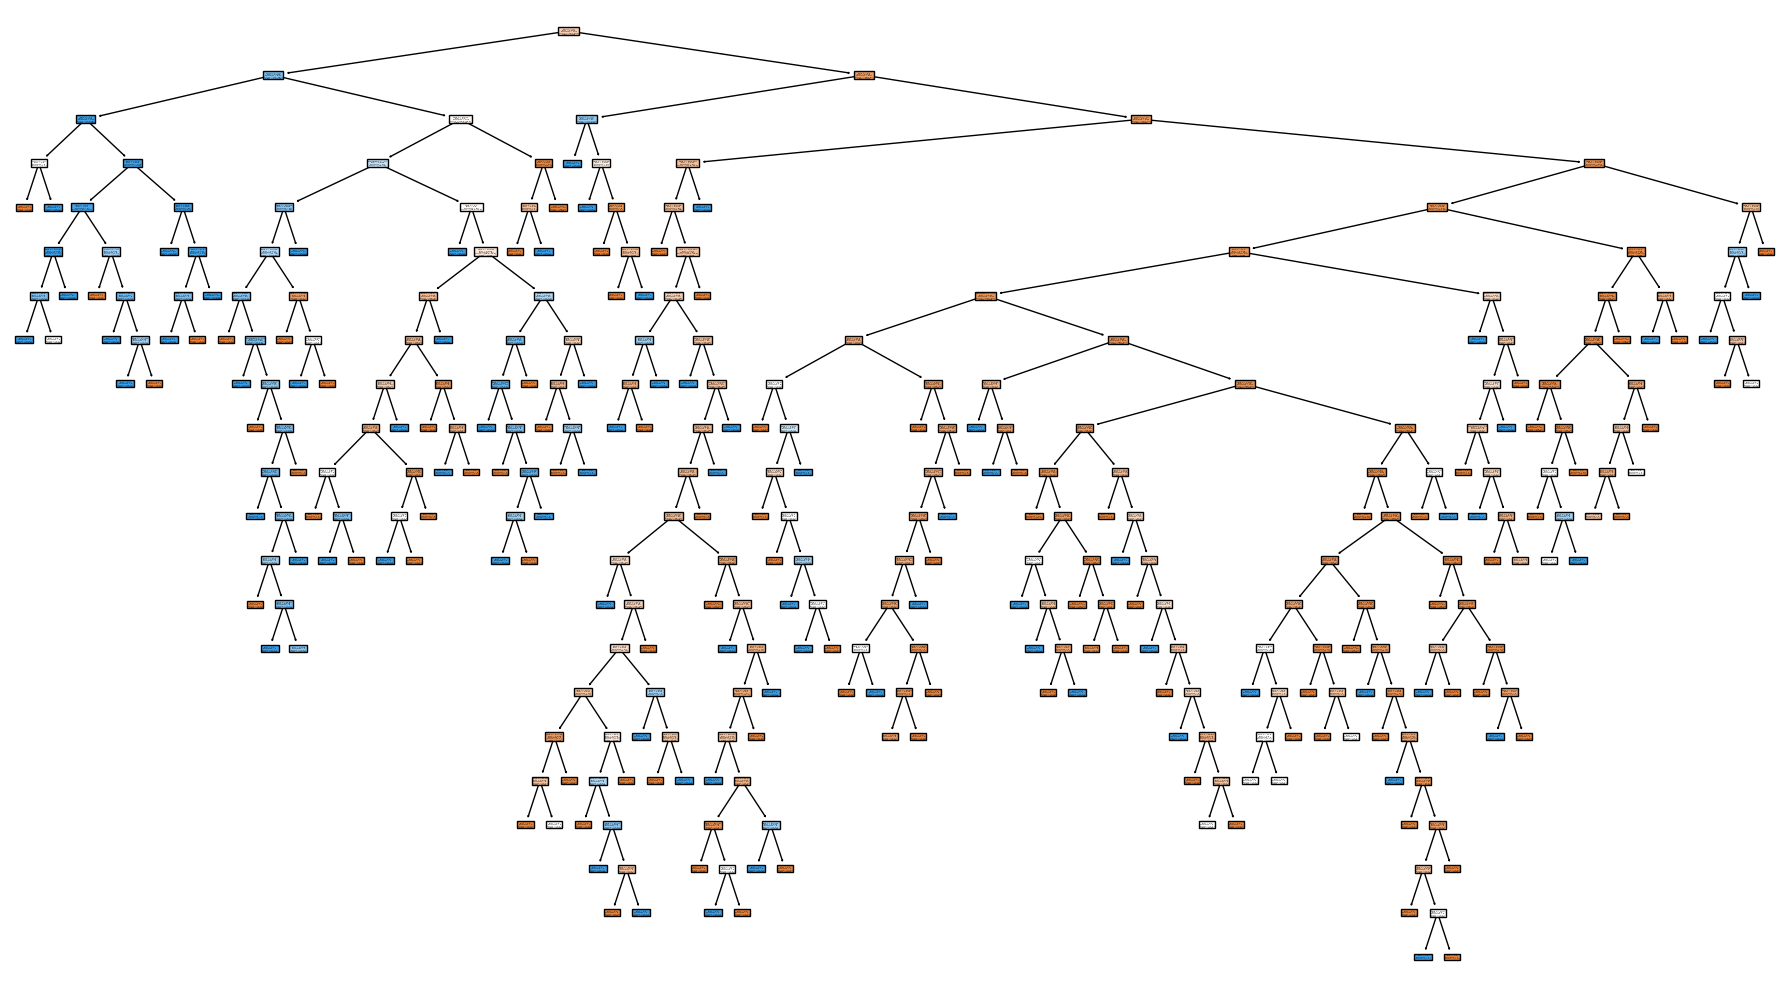

In [18]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    filled=True,
    feature_names=X.columns,
    class_names=["Died", "Survied"]
)

plt.tight_layout()
plt.show()

### Random Forest

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=601, oob_score=True, bootstrap=True, max_depth=8)

rf.fit(X_train, y_train)


y_pred = rf.predict(X_test)
y_pred_train = rf.predict(X_train)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("OOB:\t", rf.oob_score_)
print("Accuracy train:\t", accuracy_score(y_train, y_pred_train))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

Accuracy:	 0.8324022346368715
OOB:	 0.8230337078651685
Accuracy train:	 0.9199438202247191
Recall:	 0.7162162162162162
Precision:	 0.8548387096774194
F1 Scorce:	 0.7794117647058824
CM:
 [[96  9]
 [21 53]]


In [37]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression

base_model = LogisticRegression(max_iter=1000)

bagging = BaggingClassifier(
    estimator=base_model,
    n_estimators=601,
    oob_score=True,
    bootstrap=True,
)

bagging.fit(X_train, y_train)


y_pred = bagging.predict(X_test)
y_pred_train = bagging.predict(X_train)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("OOB:\t", rf.oob_score_)
print("Accuracy train:\t", accuracy_score(y_train, y_pred_train))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

Accuracy:	 0.7988826815642458
OOB:	 0.8230337078651685
Accuracy train:	 0.7935393258426966
Recall:	 0.7432432432432432
Precision:	 0.7638888888888888
F1 Scorce:	 0.7534246575342466
CM:
 [[88 17]
 [19 55]]
